In [1]:
import sys
print(sys.executable)

c:\Users\vidya\Downloads\CarbonLab_Final_Repository\interpretable-co2-adsorption-ml\.venv-ann\Scripts\python.exe


In [2]:
import sys
print(sys.executable)

import torch
print(torch.__version__)

c:\Users\vidya\Downloads\CarbonLab_Final_Repository\interpretable-co2-adsorption-ml\.venv-ann\Scripts\python.exe
2.15.0+cpu


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

device = torch.device("cpu")

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Training device:", device)

All libraries imported successfully!
PyTorch version: 2.15.0+cpu
Training device: cpu


In [4]:
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

print("Random seed set successfully!")

Random seed set successfully!


In [5]:
import json

with open("../feature_config.json", "r") as file:
    feature_config = json.load(file)

print(json.dumps(feature_config, indent=4))

{
    "target": "CO2 uptake (mmol/g)",
    "features": [
        "Surface Area (m2/g)",
        "Total Pore Volume(cm3/g)",
        "Micropore Volume (cm3/g)",
        "C (%)",
        "H (%)",
        "N (%)",
        "O (%)",
        "S (%)",
        "Temp (\u00b0C)",
        "Pressure (bar)"
    ]
}


In [6]:
df = pd.read_csv("../data/Processed_527_datapoints.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (527, 11)


,Surface Area (m2/g),Total Pore Volume(cm3/g),Micropore Volume (cm3/g),C (%),H (%),N (%),O (%),S (%),Temp (°C),Pressure (bar),CO2 uptake (mmol/g)
0,1281.6,0.71,0.32,69.22,3.99,0.08,26.30,0.40,25,1.0,2.625000
1,1012.6,0.56,0.22,64.83,3.64,0.38,30.77,0.38,25,1.0,2.586364
2,1408.8,0.83,0.36,72.41,3.63,0.01,23.59,0.37,25,1.0,2.920455
3,1403.9,0.85,0.33,69.51,4.35,0.76,24.94,0.44,25,1.0,2.438636
4,841.3,0.36,NaN,68.43,0.00,31.09,0.48,0.00,25,1.0,3.230000


In [8]:
print("Missing values in each column:\n")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDataset information:")
df.info()

Missing values in each column:

Surface Area (m2/g)           0
Total Pore Volume(cm3/g)     28
Micropore Volume (cm3/g)    210
C (%)                         0
H (%)                         0
N (%)                         0
O (%)                         0
S (%)                         0
Temp (°C)                     0
Pressure (bar)                0
CO2 uptake (mmol/g)           0
dtype: int64

Total missing values: 238

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 527 entries, 0 to 526
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Surface Area (m2/g)       527 non-null    float64
 1   Total Pore Volume(cm3/g)  499 non-null    float64
 2   Micropore Volume (cm3/g)  317 non-null    float64
 3   C (%)                     527 non-null    float64
 4   H (%)                     527 non-null    float64
 5   N (%)                     527 non-null    float64
 6   O (%)          

In [9]:
FEATURES = feature_config["features"]
TARGET = feature_config["target"]

X = df[FEATURES].copy()
y = df[TARGET].copy()

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(FEATURES)

print("\nTarget variable:", TARGET)

Input features shape: (527, 10)
Target shape: (527,)

Input features:
['Surface Area (m2/g)', 'Total Pore Volume(cm3/g)', 'Micropore Volume (cm3/g)', 'C (%)', 'H (%)', 'N (%)', 'O (%)', 'S (%)', 'Temp (°C)', 'Pressure (bar)']

Target variable: CO2 uptake (mmol/g)


In [10]:
import os

for folder in ["../data", "../artifacts", "../results"]:
    print(f"\n--- {folder} ---")

    if os.path.exists(folder):
        for item in os.listdir(folder):
            print(item)


--- ../data ---
Processed_527_datapoints.csv

--- ../artifacts ---
candidates
deployment
feature_config.json
initial_models
splits
tuned_models

--- ../results ---
advanced_model_comparison.csv
advanced_model_comparison_summary.json
advanced_model_validation_predictions.csv
ale_pressure_(bar).csv
ale_surface_area_(m2_g).csv
ale_temp_(°c).csv
ale_temp_(Γö¼Γûæc).csv
ale_temp_(┬░c).csv
all_models_best_params.json
all_model_optuna_trials.csv
baseline_results.csv
ensemble_comparison.csv
ensemble_summary.json
ensemble_validation_predictions.csv
ensemble_weights.csv
figures
final_evaluation_summary.json
final_test_predictions.csv
final_test_results.csv
hyperparameter_tuning_summary.json
initial_vs_tuned_comparison.csv
optuna_best_params.json
optuna_trials
optuna_trials.csv
shap_feature_importance.csv
tuned_catboost_validation.csv
tuned_model_comparison.csv
tuned_model_validation_predictions.csv
tuning_best_cv_results.csv


In [11]:
import os

split_folder = "../artifacts/splits"

for root, dirs, files in os.walk(split_folder):
    for file in files:
        path = os.path.join(root, file)
        print(path)

../artifacts/splits\split_assignments.csv
../artifacts/splits\split_config.json


In [12]:
split_df = pd.read_csv("../artifacts/splits/split_assignments.csv")

print("Shape:", split_df.shape)
print("\nFirst 10 rows:")
display(split_df.head(10))

print("\nColumn names:")
print(split_df.columns.tolist())

print("\nSplit distribution:")
print(split_df.iloc[:, -1].value_counts())

Shape: (526, 2)

First 10 rows:


,row_id,split
0,0,test
1,1,validation
2,2,test
3,3,train
4,4,train
5,5,train
6,6,test
7,7,train
8,8,train
9,9,test



Column names:
['row_id', 'split']

Split distribution:
split
train         336
test          106
validation     84
Name: count, dtype: int64


In [13]:
with open("../artifacts/splits/split_config.json", "r") as file:
    split_config = json.load(file)

print(json.dumps(split_config, indent=4))

{
    "random_state": 42,
    "test_size": 0.2,
    "validation_size_within_development": 0.2,
    "train_rows": 336,
    "validation_rows": 84,
    "test_rows": 106
}


In [14]:
print("Split columns:", split_df.columns.tolist())

print("\nSplit distribution:")
print(split_df.iloc[:, -1].value_counts())

print("\nTotal assigned rows:", len(split_df))

print("\nMissing row indices:")
print(sorted(set(df.index) - set(split_df.index))[:20])

Split columns: ['row_id', 'split']

Split distribution:
split
train         336
test          106
validation     84
Name: count, dtype: int64

Total assigned rows: 526

Missing row indices:
[526]


In [15]:
# Map saved row IDs to the original dataset
split_data = split_df.merge(
    df.reset_index().rename(columns={"index": "row_id"}),
    on="row_id",
    how="left"
)

# Separate the three datasets
train_df = split_data[split_data["split"] == "train"]
val_df = split_data[split_data["split"] == "validation"]
test_df = split_data[split_data["split"] == "test"]

# Extract features and target
X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_val = val_df[FEATURES]
y_val = val_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (336, 10) (336,)
Validation: (84, 10) (84,)
Testing: (106, 10) (106,)


In [16]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

print("Missing values after imputation:")
print(np.isnan(X_train_imputed).sum())
print(np.isnan(X_val_imputed).sum())
print(np.isnan(X_test_imputed).sum())

Missing values after imputation:
0
0
0


In [22]:
print("X_train_scaled:", "X_train_scaled" in globals())
print("y_train:", "y_train" in globals())
print("torch:", "torch" in globals())

X_train_scaled: False
y_train: True
torch: True


In [23]:
# Step 1: Median imputation
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

# Step 2: Feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_val_scaled = scaler.transform(X_val_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Preprocessing completed!")
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Preprocessing completed!
Training: (336, 10)
Validation: (84, 10)
Testing: (106, 10)


In [24]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

print("Training:", X_train_tensor.shape)
print("Target:", y_train_tensor.shape)
print("Batches:", len(train_loader))

Training: torch.Size([336, 10])
Target: torch.Size([336, 1])
Batches: 11


In [25]:
class ANN(nn.Module):

    def __init__(self, input_size):
        super(ANN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model = ANN(input_size=X_train_tensor.shape[1]).to(device)

print(model)

ANN(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [26]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [27]:
EPOCHS = 200
PATIENCE = 20

best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

best_model_state = None

In [28]:
for epoch in range(EPOCHS):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        predictions = model(X_val_tensor.to(device))
        val_loss = criterion(predictions, y_val_tensor.to(device))

        running_val_loss = val_loss.item()

    train_losses.append(epoch_train_loss)
    val_losses.append(running_val_loss)

    # Early stopping
    if running_val_loss < best_val_loss:
        best_val_loss = running_val_loss
        patience_counter = 0
        best_model_state = {
            key: value.detach().clone()
            for key, value in model.state_dict().items()
        }
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Val Loss: {running_val_loss:.4f}"
        )

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# Restore best model
model.load_state_dict(best_model_state)

print("\nBest validation loss:", best_val_loss)

Epoch [10/200] Train Loss: 1.8152 Val Loss: 1.4652
Epoch [20/200] Train Loss: 0.8165 Val Loss: 0.7505
Epoch [30/200] Train Loss: 0.6161 Val Loss: 0.6211
Epoch [40/200] Train Loss: 0.5302 Val Loss: 0.5315
Epoch [50/200] Train Loss: 0.4523 Val Loss: 0.4881
Epoch [60/200] Train Loss: 0.4082 Val Loss: 0.4394
Epoch [70/200] Train Loss: 0.3699 Val Loss: 0.4007
Epoch [80/200] Train Loss: 0.3431 Val Loss: 0.3685
Epoch [90/200] Train Loss: 0.3214 Val Loss: 0.3320
Epoch [100/200] Train Loss: 0.3013 Val Loss: 0.3424
Epoch [110/200] Train Loss: 0.2740 Val Loss: 0.2933
Epoch [120/200] Train Loss: 0.2527 Val Loss: 0.2996
Epoch [130/200] Train Loss: 0.2421 Val Loss: 0.2988

Early stopping at epoch 130

Best validation loss: 0.29328322410583496


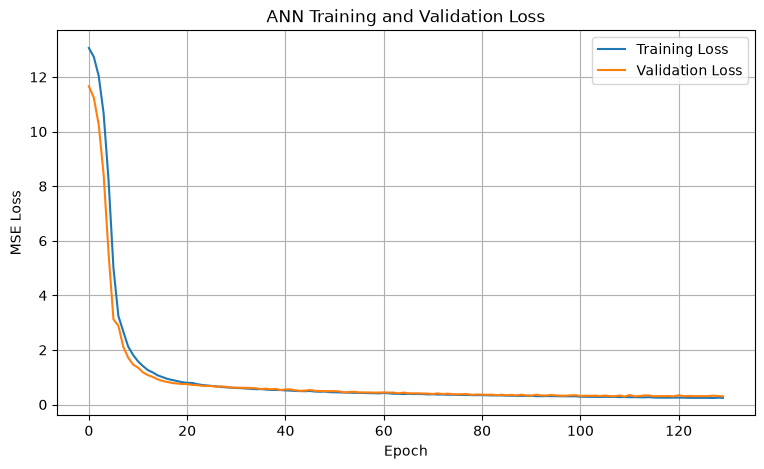

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
model.eval()

with torch.no_grad():
    test_predictions = model(X_test_tensor.to(device)).cpu().numpy()

y_actual = y_test_tensor.numpy()

mae = mean_absolute_error(y_actual, test_predictions)
mse = mean_squared_error(y_actual, test_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, test_predictions)

print("ANN Test Performance")
print("--------------------")
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

ANN Test Performance
--------------------
MAE: 0.468
MSE: 0.3695
RMSE: 0.6079
R2 Score: 0.8535


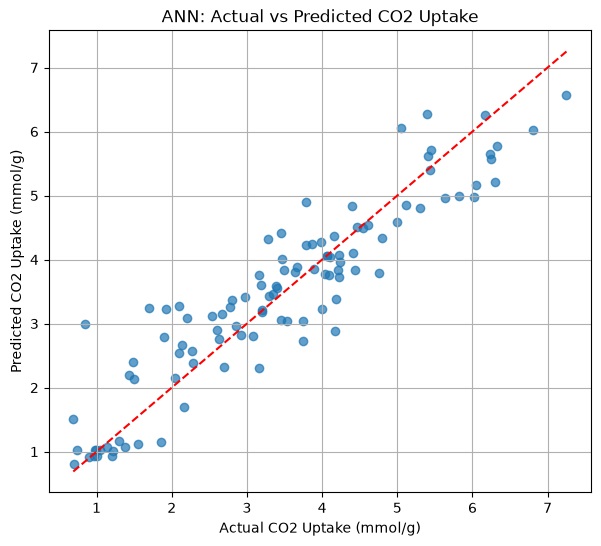

In [31]:
plt.figure(figsize=(7, 6))

plt.scatter(y_actual.flatten(), test_predictions.flatten(), alpha=0.7)

min_val = min(y_actual.min(), test_predictions.min())
max_val = max(y_actual.max(), test_predictions.max())

plt.plot([min_val, max_val], [min_val, max_val], 'r--')

plt.xlabel("Actual CO2 Uptake (mmol/g)")
plt.ylabel("Predicted CO2 Uptake (mmol/g)")
plt.title("ANN: Actual vs Predicted CO2 Uptake")
plt.grid(True)
plt.show()

In [32]:
import os
import joblib

os.makedirs("../artifacts/ann", exist_ok=True)

# Save trained model weights
torch.save(
    model.state_dict(),
    "../artifacts/ann/ann_model.pth"
)

# Save preprocessing objects
joblib.dump(
    imputer,
    "../artifacts/ann/imputer.pkl"
)

joblib.dump(
    scaler,
    "../artifacts/ann/scaler.pkl"
)

# Save model configuration
ann_config = {
    "input_size": 10,
    "hidden_layers": [64, 32, 16],
    "output_size": 1,
    "activation": "ReLU",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "best_validation_loss": best_val_loss,
    "test_MAE": mae,
    "test_RMSE": rmse,
    "test_R2": r2
}

with open("../artifacts/ann/ann_config.json", "w") as file:
    json.dump(ann_config, file, indent=4)

print("ANN model and preprocessing artifacts saved successfully!")

ANN model and preprocessing artifacts saved successfully!


In [33]:
import pandas as pd
import os

result_files = [
    "../results/advanced_model_comparison.csv",
    "../results/ensemble_comparison.csv",
    "../results/tuned_model_comparison.csv",
    "../results/baseline_results.csv"
]

for path in result_files:
    if os.path.exists(path):
        print("\n\nFILE:", os.path.basename(path))
        result = pd.read_csv(path)
        print("Shape:", result.shape)
        print("Columns:", result.columns.tolist())
        display(result.head())



FILE: advanced_model_comparison.csv
Shape: (6, 7)
Columns: ['Model', 'MAE', 'RMSE', 'R2', 'Training_Time_Seconds', 'Training_Rows', 'Validation_Rows']


,Model,MAE,RMSE,R2,Training_Time_Seconds,Training_Rows,Validation_Rows
0,CatBoost,0.376577,0.602377,0.839975,0.158930,336,84
1,LightGBM,0.427982,0.638691,0.820100,0.439086,336,84
2,XGBoost,0.403951,0.640016,0.819353,0.336969,336,84
3,Extra Trees,0.423781,0.658207,0.808938,0.095997,336,84
4,Random Forest,0.455028,0.678198,0.797156,0.198025,336,84




FILE: ensemble_comparison.csv
Shape: (9, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Validation-Optimized Weighted Ensemble,0.374145,0.575899,0.853734
1,Entropy-TOPSIS Ensemble,0.375480,0.586710,0.848191
2,CatBoost,0.390912,0.589784,0.846596
3,LightGBM,0.395260,0.598388,0.842088
4,Simple Averaging Ensemble,0.386901,0.608631,0.836635




FILE: tuned_model_comparison.csv
Shape: (6, 6)
Columns: ['Model', 'CV_RMSE', 'Validation_MAE', 'Validation_RMSE', 'Validation_R2', 'Refit_Time_Seconds']


,Model,CV_RMSE,Validation_MAE,Validation_RMSE,Validation_R2,Refit_Time_Seconds
0,CatBoost,0.761804,0.390912,0.589784,0.846596,0.065097
1,LightGBM,0.744913,0.395260,0.598388,0.842088,1.258642
2,XGBoost,0.744020,0.405134,0.615384,0.832990,0.522925
3,Gradient Boosting,0.766483,0.409320,0.664072,0.805518,0.095354
4,Extra Trees,0.785750,0.443478,0.665515,0.804672,0.055629




FILE: baseline_results.csv
Shape: (2, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,DummyRegressor,1.235768,1.527668,-0.029219
1,Ridge,0.663000,0.901264,0.641776


In [34]:
advanced = pd.read_csv(
    "../results/advanced_model_comparison.csv"
)

print(advanced.to_string(index=False))

            Model      MAE     RMSE       R2  Training_Time_Seconds  Training_Rows  Validation_Rows
         CatBoost 0.376577 0.602377 0.839975               0.158930            336               84
         LightGBM 0.427982 0.638691 0.820100               0.439086            336               84
          XGBoost 0.403951 0.640016 0.819353               0.336969            336               84
      Extra Trees 0.423781 0.658207 0.808938               0.095997            336               84
    Random Forest 0.455028 0.678198 0.797156               0.198025            336               84
Gradient Boosting 0.449556 0.693466 0.787920               0.064889            336               84


In [35]:
ensemble = pd.read_csv(
    "../results/ensemble_comparison.csv"
)

print(ensemble.to_string(index=False))

                                 Model      MAE     RMSE       R2
Validation-Optimized Weighted Ensemble 0.374145 0.575899 0.853734
               Entropy-TOPSIS Ensemble 0.375480 0.586710 0.848191
                              CatBoost 0.390912 0.589784 0.846596
                              LightGBM 0.395260 0.598388 0.842088
             Simple Averaging Ensemble 0.386901 0.608631 0.836635
                               XGBoost 0.405134 0.615384 0.832990
                     Gradient Boosting 0.409320 0.664072 0.805518
                           Extra Trees 0.443478 0.665515 0.804672
                         Random Forest 0.458213 0.677090 0.797818


In [36]:
print(advanced.columns.tolist())
print(ensemble.columns.tolist())

['Model', 'MAE', 'RMSE', 'R2', 'Training_Time_Seconds', 'Training_Rows', 'Validation_Rows']
['Model', 'MAE', 'RMSE', 'R2']


In [37]:
print(advanced[
    ["Model", "Training_Rows", "Validation_Rows"]
].to_string(index=False))

            Model  Training_Rows  Validation_Rows
         CatBoost            336               84
         LightGBM            336               84
          XGBoost            336               84
      Extra Trees            336               84
    Random Forest            336               84
Gradient Boosting            336               84


In [38]:
import os

for folder in ["../artifacts", "../results"]:
    print(f"\n--- {folder} ---")

    for root, dirs, files in os.walk(folder):
        for file in files:
            if "test" in file.lower() or "prediction" in file.lower():
                print(os.path.join(root, file))


--- ../artifacts ---
../artifacts\candidates\20261028T094742Z_ensemble\final_test_evaluation.json
../artifacts\candidates\20261028T094742Z_ensemble\explainability\ensemble_shap_predictions.csv

--- ../results ---
../results\advanced_model_validation_predictions.csv
../results\ensemble_validation_predictions.csv
../results\final_test_predictions.csv
../results\final_test_results.csv
../results\tuned_model_validation_predictions.csv
../results\figures\final_test_actual_vs_predicted.png
../results\figures\final_test_residuals.png


In [39]:
final_results = pd.read_csv("../results/final_test_results.csv")

print("Final test results:")
display(final_results)

Final test results:


,Model,MAE,RMSE,R2
0,Validation-Optimized Weighted Ensemble,0.521952,0.706357,0.817291
1,LightGBM,0.521067,0.710412,0.815187
2,XGBoost,0.523388,0.715134,0.812722
3,Gradient Boosting,0.528939,0.721782,0.809224
4,CatBoost,0.544538,0.735531,0.801887
5,Random Forest,0.589856,0.799206,0.766101
6,Extra Trees,0.595238,0.802355,0.764254


In [40]:
final_predictions = pd.read_csv(
    "../results/final_test_predictions.csv"
)

print("Shape:", final_predictions.shape)
print("Columns:", final_predictions.columns.tolist())

display(final_predictions.head())

Shape: (106, 10)
Columns: ['row_id', 'Actual_CO2_uptake', 'Weighted_Ensemble_Prediction', 'CatBoost_Prediction', 'random_forest_prediction', 'extra_trees_prediction', 'gradient_boosting_prediction', 'xgboost_prediction', 'lightgbm_prediction', 'catboost_prediction']


,row_id,Actual_CO2_uptake,Weighted_Ensemble_Prediction,CatBoost_Prediction,random_forest_prediction,extra_trees_prediction,gradient_boosting_prediction,xgboost_prediction,lightgbm_prediction,catboost_prediction
0,0,2.625000,2.922638,2.939862,2.840022,2.941824,2.921013,2.547797,3.128529,2.939862
1,2,2.920455,3.166330,3.162074,2.866865,3.062866,3.254292,2.811960,3.401555,3.162074
2,6,3.450000,2.560011,2.631707,2.463327,2.971836,2.626968,2.456153,2.484837,2.631707
3,9,4.540000,3.755270,3.761286,3.477538,3.481333,3.747573,3.858414,3.677364,3.761286
4,10,4.460000,3.403861,3.291745,3.309352,3.467999,3.450937,3.410179,3.621327,3.291745


In [41]:
with open(
    "../artifacts/candidates/20261028T094742Z_ensemble/final_test_evaluation.json",
    "r"
) as file:
    final_eval = json.load(file)

print(json.dumps(final_eval, indent=4))

{
    "candidate_directory": "artifacts/candidates/20261028T094742Z_ensemble",
    "target_column": "CO2 uptake (mmol/g)",
    "prediction_unit": "mmol/g",
    "test_rows": 106,
    "test_set_evaluated": true,
    "ensemble_strategy": "optimized_nonnegative_weights",
    "ensemble_weights": {
        "Random Forest": 2.4620441927086902e-18,
        "Extra Trees": 3.0923328966184142e-18,
        "Gradient Boosting": 4.068114851855368e-18,
        "XGBoost": 0.09456358094464602,
        "LightGBM": 0.40591666278510136,
        "CatBoost": 0.4995197562702527
    },
    "metrics": {
        "MAE": 0.489638354750637,
        "RMSE": 0.684040173725787,
        "R2": 0.8286537599919848
    },
    "note": "Final evaluation of the selected candidate on the original held-out test split. Do not use these results to tune weights or select models."
}


In [42]:
print("JSON evaluation:")
print(final_eval["metrics"])

print("\nCSV final test results:")
print(final_results.to_string(index=False))

print("\nANN test results:")
print({
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
})

JSON evaluation:
{'MAE': 0.489638354750637, 'RMSE': 0.684040173725787, 'R2': 0.8286537599919848}

CSV final test results:
                                 Model      MAE     RMSE       R2
Validation-Optimized Weighted Ensemble 0.521952 0.706357 0.817291
                              LightGBM 0.521067 0.710412 0.815187
                               XGBoost 0.523388 0.715134 0.812722
                     Gradient Boosting 0.528939 0.721782 0.809224
                              CatBoost 0.544538 0.735531 0.801887
                         Random Forest 0.589856 0.799206 0.766101
                           Extra Trees 0.595238 0.802355 0.764254

ANN test results:
{'MAE': 0.46796107292175293, 'RMSE': np.float64(0.6078876537156742), 'R2': 0.8534983396530151}


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create ANN prediction table
ann_results = pd.DataFrame({
    "row_id": test_df["row_id"].values,
    "ANN_Prediction": test_predictions.flatten()
})

# Match ANN and ensemble predictions using row_id
comparison = final_predictions.merge(
    ann_results,
    on="row_id",
    how="inner"
)

actual = comparison["Actual_CO2_uptake"]
ensemble_pred = comparison["Weighted_Ensemble_Prediction"]
ann_pred = comparison["ANN_Prediction"]

print("Matched test observations:", len(comparison))

for name, pred in [
    ("Weighted Ensemble", ensemble_pred),
    ("ANN", ann_pred)
]:
    print(f"\n{name}")
    print("MAE:", mean_absolute_error(actual, pred))
    print("RMSE:", np.sqrt(mean_squared_error(actual, pred)))
    print("R2:", r2_score(actual, pred))

Matched test observations: 106

Weighted Ensemble
MAE: 0.5219517818143666
RMSE: 0.7063571567459624
R2: 0.8172909493373284

ANN
MAE: 0.6031678192550076
RMSE: 0.8878384751186874
R2: 0.7113448670314546


In [45]:
ann_results = pd.DataFrame({
    "row_id": test_df["row_id"].to_numpy(),
    "ANN_actual": y_test.to_numpy(),
    "ANN_Prediction": test_predictions.flatten()
})

comparison = final_predictions.merge(
    ann_results,
    on="row_id",
    how="inner"
)

print("Matched observations:", len(comparison))

print(
    "Actual values match:",
    np.allclose(
        comparison["Actual_CO2_uptake"],
        comparison["ANN_actual"]
    )
)

print(comparison[
    ["row_id", "Actual_CO2_uptake", "ANN_actual", "ANN_Prediction"]
].head(10).to_string(index=False))


Matched observations: 106
Actual values match: False
 row_id  Actual_CO2_uptake  ANN_actual  ANN_Prediction
      0           2.625000    2.625000        2.761024
      2           2.920455    2.920455        2.820306
      6           3.450000    3.450000        3.052762
      9           4.540000    4.540000        4.492854
     10           4.460000    4.460000        4.503369
     11           3.780000    3.780000        4.902820
     15           1.300000    1.300000        1.164806
     18           4.210000    4.210000        3.841640
     22           3.350000    3.350000        3.459388
     30           3.400000    3.400000        3.557365
